#**Анализ рынка недвижимости в Казани: однокомнатные квартиры и студии**

**Цель**:  Проанализировать рынок студий и однокомнатных квартир в Казани, чтобы понять, сколько стоит типичное жилье, какие районы доступнее, чем отличаются новостройки и вторичка, и какие факторы сильнее всего влияют на цену за кв.м.




##**Этапы работы**

**1 Подготовка данных**

1.1 Загрузка и первичный осмотр

1.2 Работа с пропусками и типами

1.3 Нормализация районов

1.4 Метро и параметры дома

1.5 Выбросы

**2 Общая картина рынка**

2.1 Объекты на рынке

2.2 Цены

2.3 Сравнение в одинаковом диапазоне

Вывод по главе 2

**3 Ценообразование на рынке**

3.1 Влияение метро

3.2 Влияние возраста дома

3.3 Этажность дома и этаж

3.4 Влияние района

3.5 Влияние ЖК

3.6 Портреты премиум-объекта и объекта из массового сегмента

Вывод по главе 3



###**1 Подготовка данных**

In [ ]:
#Импортируем все необходимые в дальнейшем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

**1.1 Загрузка и первичный осмотр**

In [ ]:
df = pd.read_csv("/content/avito_kvart.txt", sep="|")
df.head()

,layout,type,district,residential_complex,area,total_floors,floor,year_built,completion_year,metro_walk,metro_stations,price,price_per_m2
0,студия,Вторичка,Приволжский,NaN,30.6,26.0,13.0,2025.0,NaN,Дубравная (31 мин.),Дубравная,8 650 000₽,282680.0
1,однушка,Новостройка,Советский,ЖК «Мой Ритм»,38.1,24.0,8.0,NaN,2030.0,NaN,NaN,9 598 732₽,251935.0
2,однушка,Вторичка,Советский,NaN,38.9,9.0,1.0,2006.0,NaN,"Горки (31 мин.), Проспект Победы (31 мин.), Ду...","Горки, Проспект Победы, Дубравная",8 700 000₽,223650.0
3,однушка,Новостройка,Советский,ЖК «Наследие»,38.9,16.0,7.0,NaN,2027.0,"Аметьево (31 мин.), Горки (11–15 мин.), Проспе...","Аметьево, Горки, Проспект Победы",8 900 000₽,228792.0
4,однушка,Новостройка,Советский,Нокса Парк,34.7,18.0,14.0,NaN,2024.0,NaN,NaN,5 900 000₽,170029.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6594 entries, 0 to 6593
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   layout               6594 non-null   object 
 1   type                 6587 non-null   object 
 2   district             6572 non-null   object 
 3   residential_complex  3760 non-null   object 
 4   area                 6587 non-null   float64
 5   total_floors         6587 non-null   float64
 6   floor                6587 non-null   float64
 7   year_built           2742 non-null   float64
 8   completion_year      3759 non-null   float64
 9   metro_walk           3835 non-null   object 
 10  metro_stations       3835 non-null   object 
 11  price                6587 non-null   object 
 12  price_per_m2         6587 non-null   float64
dtypes: float64(6), object(7)
memory usage: 669.8+ KB


In [ ]:
n = df.shape[0]
print(f"Общее количество записей в датафрейме: {n}\n")
print("Количество пропусков по каждой колонке:")
for i in df.columns:
    missing_count = n - df[i].notna().sum()
    print(f"Пропусков для {i}: {missing_count}")

Общее количество записей в датафрейме: 6594

Количество пропусков по каждой колонке:
Пропусков для layout: 0
Пропусков для type: 7
Пропусков для district: 22
Пропусков для residential_complex: 2834
Пропусков для area: 7
Пропусков для total_floors: 7
Пропусков для floor: 7
Пропусков для year_built: 3852
Пропусков для completion_year: 2835
Пропусков для metro_walk: 2759
Пропусков для metro_stations: 2759
Пропусков для price: 7
Пропусков для price_per_m2: 7


Датасет содержит **6594 объявления** о продаже студий и однокомнатных квартир
в Казани и пригороде, собранных с Avito. Всего 13 колонок.

**Категориальные признаки:**
- `layout` — планировка: студия или однушка. Пропусков нет.
- `type` — тип жилья: новостройка или вторичка. 7 пропусков.
- `district` — район города. 22 пропуска.
- `residential_complex` — название ЖК. Заполнено только у 3760 объявлений —
  это норма: у вторички ЖК обычно не указывают.
- `metro_walk` — ближайшие станции метро с временем ходьбы. Заполнено
  у 3835 объявлений.
- `metro_stations` — те же станции без времени. Дублирует `metro_walk`.
- `price` — цена в рублях, но хранится как **строка** из-за символа ₽
  и пробелов. Требует очистки.

**Числовые признаки:**
- `area` — площадь, м².
- `total_floors` — этажность дома.
- `floor` — этаж квартиры.
- `year_built` — год постройки дома. Заполнено только у 2742 объектов —
  это вторичка.
- `completion_year` — год сдачи новостройки. Заполнено у 3759 объектов.
- `price_per_m2` — цена за м².

**Что бросается в глаза:**
1. В колонках `type`, `district`, `area`, `total_floors`, `floor`,
   `price`, `price_per_m2` — ровно **7 пропусков**. Скорее всего, строки, где пусто во всех ключевых полях сразу.
2. `year_built` и `completion_year` — у вторички
   заполнен первый, у новостроек второй. Логично объединить их в одну
   колонку `year_actual`.
3. `price` хранится строкой — нужно убрать ₽ и пробелы, привести к float.
4. `metro_walk` содержит несколько станций в одной ячейке — можно
   распарсить и вытащить ближайшую.
5. `residential_complex`— заполнено меньше чем в половине строк, особенность данных.

**План работы с данными:**
1. Удалить 7 пустых строк.
2. Очистить `price` и привести типы к `Int64`.
3. Нормализовать названия районов, удалить мусорные значения.
4. Распарсить `metro_walk` до ближайшей станции и времени ходьбы.
5. Объединить `year_built` и `completion_year` в `year_actual`.
6. Проверить выбросы и обработать.

**1.2 Работа с пропусками и типами**

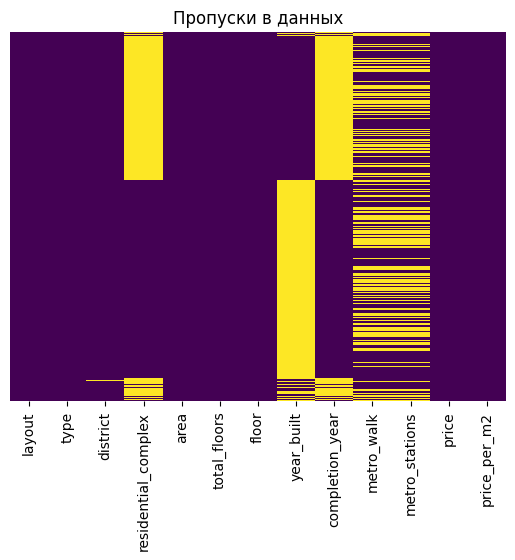

In [ ]:
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Пропуски в данных');

In [ ]:
# Удалим полностью пустые строки
df_na = df[df['type'].isna()]
df = df.drop(df_na.index)

In [ ]:
# У колонки price тип object, при парсинге остались символы ₽ и пробелы. Исправим это
df['price'] = df['price'].astype(str).str.replace('₽', '').str.replace("от", "")
df['price'] = df['price'].str.split().str.join('')
df['price'] = df['price'].astype(float)
df['price'].dtype

dtype('float64')

In [ ]:
# Год сдачи дома/год постройки дома/этажность дома/этаж имеют тип float исправим на целое число
df['year_built'] = df['year_built'].astype('Int64')
df['completion_year'] = df['completion_year'].astype('Int64')
df['total_floors'] = df['total_floors'].astype('Int64')
df['floor'] = df['floor'].astype('Int64')

**1.3 Нормализация районов**

In [ ]:
df["district"].unique()

array(['Приволжский', 'Советский', 'Кировский', 'Авиастроительный',
       'Ново-Савиновский', 'Вахитовский', 'Зеленодольский', 'Московский',
       'Азино-', 'Лаишевский', 'Родины', 'Пестречинский', 'Ново-',
       'Развитый', 'Савиновский', 'Престижный', 'Верхнеуслонский',
       'Высокогорский', 'Развивающийся', 'Горки-', 'Подробнее', 'Жилой',
       'Этот', nan, 'Удачный', 'Волжские', 'Уютный', 'Казани', 'Данный',
       'Шикарный', 'Адмиралтейская', 'Тандема', 'Ква', 'Старо-', 'Про',
       'Динамичный', 'Дубравнаяот', 'Ягодная', 'Ново-савиновский',
       'Площадь', 'Суконная'], dtype=object)

В данные попали районы пригорода (Зеленодольский, Лаишевский, Пестречинский, Верхнеуслонский, Высокогорский). Так как я анализирую рынок Казани, эти строки я удалю, ценности для анализа они не представляют. Названия районов приведу к единому виду. Строки с мусорными значениями удалять не буду, но помечу их как пропуски.

In [ ]:
df['district'] = df['district'].astype(str).str.strip().str.lower()
district_map = {
    "ново-":              "ново-савиновский",
    "ново-савиновский":   "ново-савиновский",
    "савиновский":        "ново-савиновский",
    "горки-":             "приволжский",
    "азино-":             "советский",
    "дубравнаяот":        "приволжский",
    "адмиралтейская":     "кировский",
    "ягодная":            "кировский",  # Ягодная слобода = Кировский район
    "ягоднаяот":          "кировский",
    "площадь":            "вахитовский",   # Площадь Тукая = Вахитовский
    "суконная":           "вахитовский",   # Суконная слобода = Вахитовский
}

df['district'] = df['district'].replace(district_map)
kazan_districts = [
    "авиастроительный",
    "вахитовский",
    "кировский",
    "московский",
    "ново-савиновский",
    "приволжский",
    "советский",
]
suburban = [
    "зеленодольский", "лаишевский", "пестречинский",
    "верхнеуслонский", "высокогорский",
]


df = df[~df['district'].isin(suburban)]
df.loc[~df['district'].isin(kazan_districts), 'district'] = np.nan
df['district'].isna().sum()

np.int64(79)

In [ ]:
# Создадим дополнительную колонку, которая показывает есть ли ЖК у дома
df['has_residential_complex'] = df['residential_complex'].notna()

**1.4 Метро и параметры дома**

In [ ]:
df['metro_stations'].unique()

array(['Дубравная', nan, 'Горки, Проспект Победы, Дубравная',
       'Аметьево, Горки, Проспект Победы', 'Проспект Победы, Дубравная',
       'Площадь Тукая, Суконная слобода, Аметьево', 'Северный вокзал',
       'Северный вокзал, Яшьлек, Козья Слобода',
       'Кремлёвская, Площадь Тукая, Суконная слобода',
       'Авиастроительная, Северный вокзал, Яшьлек',
       'Суконная слобода, Аметьево, Горки',
       'Площадь Тукая, Суконная слобода',
       'Яшьлек, Козья Слобода, Кремлёвская',
       'Кремлёвская, Суконная слобода',
       'Авиастроительная, Северный вокзал', 'Горки',
       'Суконная слобода, Аметьево', 'Суконная слобода', 'Аметьево',
       'Северный вокзал, Козья Слобода', 'Горки, Проспект Победы',
       'Горки, Дубравная', 'До метро', 'Яшьлек, Кремлёвская',
       'Площадь Тукая, Горки, Проспект Победы, Дубравная',
       'Авиастроительная, Северный вокзал, Козья Слобода',
       'Аметьево, Проспект Победы', 'Северный вокзал, Яшьлек',
       'Козья Слобода, Кремлёвская'

Есть мусорные значения, нужно привести все к правильному виду.

In [ ]:
# Напишем функцию, которая будет брать из строки ближайшее метро и время пешком до него
df['metro_walk'] = df['metro_walk'].str.lower()

def parse_metro(x):
    if pd.isna(x):
        return (np.nan, np.nan)

    str_list = [i.strip() for i in x.split(',')]
    best_station, min_minut = '', 1000

    for i in str_list:
        station = i.split('(')[0].strip()
        minut_str = i.split('(')[1].strip()

        minut_str_filter = ''.join(filter(str.isdigit, minut_str))
        minut = int(minut_str_filter[-2:])

        if minut < min_minut:
            min_minut = minut
            best_station = station

    return (best_station, min_minut)

In [ ]:
# Применяя функцию parse_metro получим две новые колонки metro_nearest и metro_min, которые показывают
# ближайшую станцию и время до нее
df[['metro_nearest', 'metro_min']] = df['metro_walk'].apply(
    lambda x: pd.Series(parse_metro(x))
)
# Проверим, что ничего не потеряли
parsed = df['metro_nearest'].notna().sum()
total_with_metro = df['metro_walk'].notna().sum()
print(f'С метро: {total_with_metro}')
print(f'Распарсилось: {parsed}')
print(f'Потеряли: {total_with_metro - parsed}')

С метро: 3763
Распарсилось: 3763
Потеряли: 0


In [ ]:
df['metro_nearest'].value_counts().reset_index()

,metro_nearest,count
0,горки,777
1,аметьево,448
2,суконная слобода,432
3,площадь тукая,367
4,проспект победы,331
5,авиастроительная,295
6,козья слобода,295
7,северный вокзал,261
8,яшьлек,223
9,дубравная,176


Уберем мусорные значения и приведем к правильному виду.

In [ ]:
mask = (df['metro_nearest'] == 'до метро') | (df['metro_nearest'] == 'дом после капитального ремонта до метро')
df.loc[mask, 'metro_nearest'] = 'неизвестное'

mask = (df['metro_nearest'] == 'до остановки') | (df['metro_nearest'] == 'парка горького -') | (df['metro_nearest'] == 'казани')
df.loc[mask, ['metro_nearest', 'metro_min']] = np.nan, np.nan

mask = df['metro_nearest'] == 'до станции метро козья слобода'
df.loc[mask, 'metro_nearest'] = 'козья слобода'

In [ ]:
# Создадим еще колонку, которая будет показывать есть ли метро у объекта
df['has_metro'] = df['metro_min'].notna()

In [ ]:
# Создадим две новые колонки: year_actual, объединив два столбца (год постройки и год сдачи дома), и age - возраст дома
df['year_actual'] = df['year_built'].fillna(df['completion_year'])
df['age'] = 2026 - df['year_actual']

In [ ]:
# Создадим дополнительную колонку с категорией возраста дома
labels = ['строится', '0-5', '6-15', '16-30', '31-50', '50+']
bins = [-np.inf, -1, 5, 15, 30, 50, np.inf]

df['age_bin'] = pd.cut(df['age'], bins=bins, labels=labels)
df['age_bin'] = df['age_bin'].astype(str)
df.loc[df['age_bin']==str(np.nan), 'age_bin'] = 'неизвестно'

In [ ]:
# Создадим дополнительную колонку с категорией этажности дома
labels = ['до 5', '6-9', '10-16', '17+']
bins = [0, 5, 9, 16, 100]

df['floors_bin'] = pd.cut(df['total_floors'], bins=bins, labels=labels)
df['floors_bin'] = df['floors_bin'].astype(str)

**1.5 Выбросы**

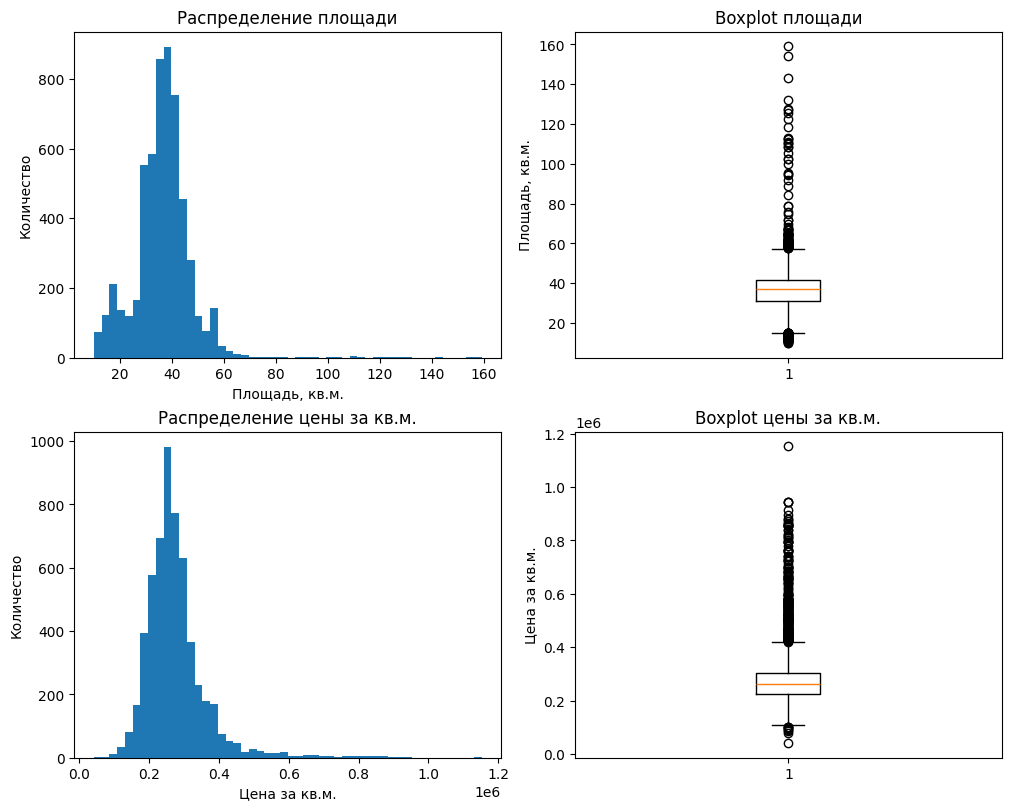

In [ ]:
# Проверим на выбросы площадь квартир и цену за квадратный метр
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')

axes[0, 0].hist(df['area'], bins=50)
axes[0, 0].set_title('Распределение площади')
axes[0, 0].set_xlabel('Площадь, кв.м.')
axes[0, 0].set_ylabel('Количество')

axes[0, 1].boxplot(df['area'])
axes[0, 1].set_title('Boxplot площади')
axes[0, 1].set_ylabel('Площадь, кв.м.')


axes[1, 0].hist(df['price_per_m2'], bins=50)
axes[1, 0].set_title('Распределение цены за кв.м.')
axes[1, 0].set_xlabel('Цена за кв.м.')
axes[1, 0].set_ylabel('Количество')

axes[1, 1].boxplot(df['price_per_m2'])
axes[1, 1].set_title('Boxplot цены за кв.м.')
axes[1, 1].set_ylabel('Цена за кв.м.');

Распределения площади и цены за кв.м. скошены, имеют длинный правй хвост. В дальнейшем лучше смотреть медианы.

In [ ]:
# Применим IQR-метод для определения выбросов
def find_iqr(x, k=1.5):
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1
    low = round(Q1 - k * IQR, 2)
    upp = round(Q3 + k * IQR, 2)
    return (low, upp)

low_area, upp_area = find_iqr(df['area'])
print(f'Границы нормы для площади: {low_area:.2f} - {upp_area:.2f}')
low_price_per_m2, upp_price_per_m2 = find_iqr(df['price_per_m2'])
print(f'Границы нормы для цены за кв.м.: {low_price_per_m2:.0f} - {upp_price_per_m2:.0f}')

Границы нормы для площади: 15.10 - 57.50
Границы нормы для цены за кв.м.: 106303 - 420653


In [ ]:
# Посмотрим на строки, которые оказались ниже нормальной цены за кв.м.
df[df['price_per_m2'] < low_price_per_m2].sort_values('price_per_m2').head(5)

,layout,type,district,residential_complex,area,total_floors,floor,year_built,completion_year,metro_walk,...,price,price_per_m2,has_residential_complex,metro_nearest,metro_min,has_metro,year_actual,age,age_bin,floors_bin
680,студия,Вторичка,ново-савиновский,NaN,95.0,10,1,1998,<NA>,"северный вокзал (31 мин.), яшьлек (21–30 мин.)...",...,3990000.0,42000.0,False,козья слобода,20.0,True,1998,28,16-30,10-16
213,студия,Вторичка,ново-савиновский,NaN,56.0,9,1,1992,<NA>,"северный вокзал (31 мин.), яшьлек (31 мин.), к...",...,4450000.0,79464.0,False,северный вокзал,31.0,True,1992,34,31-50,6-9
1532,студия,Вторичка,советский,NaN,42.0,3,2,1998,<NA>,NaN,...,3650000.0,86905.0,False,NaN,NaN,False,1998,28,16-30,до 5
557,студия,Вторичка,кировский,NaN,21.8,9,5,1980,<NA>,NaN,...,1950000.0,89450.0,False,NaN,NaN,False,1980,46,31-50,6-9
2025,однушка,Вторичка,советский,NaN,40.0,2,2,1955,<NA>,NaN,...,3750000.0,93750.0,False,NaN,NaN,False,1955,71,50+,до 5


Строки 213 и 680 достаточно большие по площади (56 и 95 кв.м.), но имеют очень маленькую цену за кв.м. (79-42 тыс.).

In [ ]:
# И посмотрим на подозрительную строку, которая оказалась на самом верху по цене за кв.м.
df[df['price_per_m2'] > upp_price_per_m2].sort_values('price_per_m2', ascending=False).head(1)

,layout,type,district,residential_complex,area,total_floors,floor,year_built,completion_year,metro_walk,...,price,price_per_m2,has_residential_complex,metro_nearest,metro_min,has_metro,year_actual,age,age_bin,floors_bin
574,студия,Вторичка,московский,NaN,19.1,5,4,1956,<NA>,"северный вокзал (11–15 мин.), козья слобода (2...",...,22000000.0,1151832.0,False,северный вокзал,15.0,True,1956,70,50+,до 5


Строка 574 - маленькая студия в старом доме, но стоит более 1 млн.р. за кв.м. Скорее всего это ошибка.

Есть предположение, что квартиры с большой площадью и маленькой ценой за кв.м. являются долями и реальная площадь объекта меньше. Есть конечно большие студии с высокой ценой, возможно премиум-сегмент.

Удалим квартиры со слишком низкой ценой за кв.м., чтобы не искажали распределение. Премиум-сегмент сохраним и пометим отдельной колонкой. Студии маленькие по площади, но с большим ценником тоже удалим.

In [ ]:
# Уберем выбросы опираясь на медианные значения цены за кв.м. и площади
median_price_per_m2 = df['price_per_m2'].median()
print(f'Медианное значение цены за кв.м.: {median_price_per_m2}')
median_area = df['area'].median()
print(f'Медианное значение площади: {median_area}')

before = len(df)

# Если площадь квартиры больше медианы, а цена за квадратный метр в два раза меньше медианы,
# то скорее всего это доля или ошибка
df = df[~((df['price_per_m2'] < median_price_per_m2/2) & (df['area'] > median_area))]

# Удалим и квартиры и слишком маленькие квартиры (меньше медианы по площади),
# но с огромной ценой за кв.м.
df = df[~((df['price_per_m2'] > median_price_per_m2*2) & (df['area'] < median_area))]

print(f'Удалено: {before - len(df)} строк')

Медианное значение цены за кв.м.: 260969.0
Медианное значение площади: 36.9
Удалено: 59 строк


In [ ]:
# Добавим дополнительную колонку, которая будет показывать, является ли квартира премиум-сегментом.
# Пусть премиум будет в 1,5 раза выше медианы
PREMIUM = median_price_per_m2 * 1.5
df['is_premium'] = (df['price_per_m2'] > PREMIUM)
print(f'Премиум имеет цену за кв.м. от {PREMIUM}')

Премиум имеет цену за кв.м. от 391453.5


In [ ]:
#from google.colab import files
#df.to_csv("avito_kvart_clean.txt", sep="|", index=False)
#files.download("avito_kvart_clean.txt")

###**2 Общая картина рынка**

**2.1 Объекты на рынке**

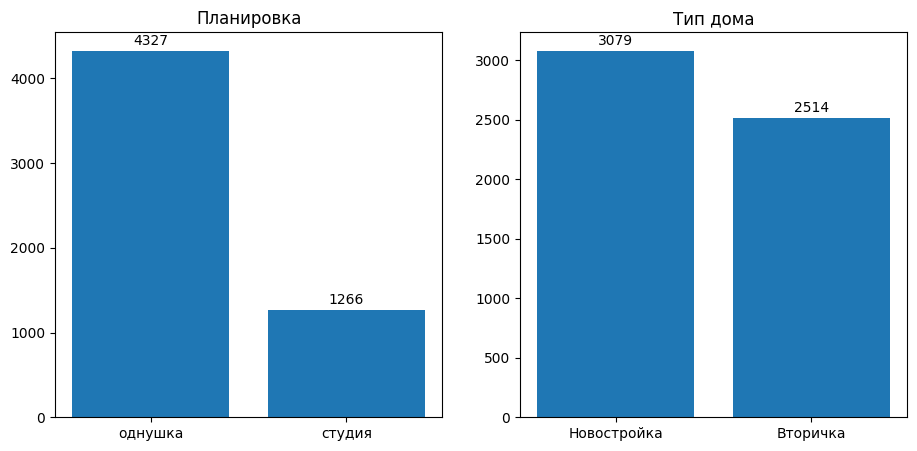

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

counts_layout = df['layout'].value_counts()
counts_type = df['type'].value_counts()

bar0 = axes[0].bar(counts_layout.index, counts_layout.values)
axes[0].bar_label(bar0, padding=2)
axes[0].set_title('Планировка')

bar1 = axes[1].bar(counts_type.index, counts_type.values)
axes[1].bar_label(bar1, padding=2)
axes[1].set_title('Тип дома');

In [ ]:
# Посмотрим доли
counts_layout = df['layout'].value_counts(normalize=True)
counts_type = df['type'].value_counts(normalize=True)
print(counts_layout, end='\n\n')
print(counts_type)

layout
однушка    0.773646
студия     0.226354
Name: proportion, dtype: float64

type
Новостройка    0.55051
Вторичка       0.44949
Name: proportion, dtype: float64


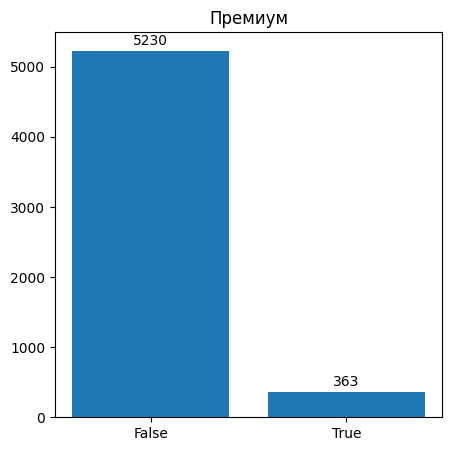

In [ ]:
counts_is_premium = df['is_premium'].value_counts()
plt.figure(figsize=(5, 5))
bar = plt.bar(counts_is_premium.index.astype(str), counts_is_premium.values)
plt.bar_label(bar, padding=2)
plt.title('Премиум');

In [ ]:
# Посмотрим долю премиума
counts_is_premium = df['is_premium'].value_counts(normalize=True)
counts_is_premium.reset_index()

,is_premium,proportion
0,False,0.935097
1,True,0.064903


In [ ]:
type_med = df.pivot_table(index='layout', columns='type', values='area', aggfunc='count', margins=True)
type_med

type,Вторичка,Новостройка,All
layout,,,
однушка,1818,2509,4327
студия,696,570,1266
All,2514,3079,5593


In [ ]:
pd.crosstab(df['layout'], df['type'], normalize='index').round(4) * 100

type,Вторичка,Новостройка
layout,,
однушка,42.02,57.98
студия,54.98,45.02


Студии чаще встречаются на вторичном рынке (в 55% случаев), а однокомнатных квартиры в новостройке (в 58%).

In [ ]:
df.pivot_table(index='is_premium', columns='type', values='area', aggfunc='count', margins=True)

type,Вторичка,Новостройка,All
is_premium,,,
False,2429,2801,5230
True,85,278,363
All,2514,3079,5593


Премиум-сегмент чаще встречается в новостройках.

**2.2 Цены**

In [ ]:
# Посмотрим медианные значения по всей выборке
df[['area', 'price_per_m2', 'price']].median().reset_index().rename(columns={'index': 'параметр', 0: 'медиана'})

,параметр,медиана
0,area,36.9
1,price_per_m2,260488.0
2,price,9846534.0


In [ ]:
# Посмотрим медианы по типу планировки
med = df.groupby('layout')[['area', 'price_per_m2', 'price']].median()
med.reset_index()

,layout,area,price_per_m2,price
0,однушка,38.9,256826.0,10276515.0
1,студия,27.4,285779.5,7700000.0


In [ ]:
stud = med.loc['студия']
one  = med.loc['однушка']
print(f'Медианная площадь однушек больше, чем у студий, на {one['area'] - stud['area']:.2f} кв.м.')
print(f'Медианная цена за кв.м. выше у студий на {stud['price_per_m2'] - one['price_per_m2']:.2f} руб.')
print(f'Медианная цена однушки выше, чем у студии, на {one['price'] - stud['price']:.2f} руб.')

Медианная площадь однушек больше, чем у студий, на 11.50 кв.м.
Медианная цена за кв.м. выше у студий на 28953.50 руб.
Медианная цена однушки выше, чем у студии, на 2576515.00 руб.


Однокомнатные квартиры больше по площади и дешевле за кв.м. При этом в новостройках чаще встречаются однокомнатные квартиры.

In [ ]:
# Посмотрим медианы для типа жилья
med = df.groupby('type')[['area', 'price_per_m2', 'price']].median()
med.reset_index()

,type,area,price_per_m2,price
0,Вторичка,34.0,236329.5,7900000.0
1,Новостройка,38.9,279211.0,10519080.0


На вторичном рынке квартиры дешевле. Тогда почему медианная цена за кв.м. студий выходит выше? Возможно за счет того, что медианная площадь студий меньше (27.4 против 38.9).

In [ ]:
# Посмотрим медианы в зависимости от того премиум или нет
med = df.groupby('is_premium')[['area', 'price_per_m2', 'price']].median()
med.reset_index()

,is_premium,area,price_per_m2,price
0,False,36.8,256962.0,9650000.0
1,True,38.2,448980.0,16629500.0


Площадь почти одинаковая: 36,8 vs 38,2 кв.м. А цена за кв.м. при этом отличается почти в 2 раза.

In [ ]:
# Посмотрим медианы цены за кв.м. премиума и массового сегмента в зависимости от типа дома
prem_type = df[df['is_premium']].groupby(['type'])['price_per_m2'].median()
prem_type.reset_index()

,type,price_per_m2
0,Вторичка,451613.0
1,Новостройка,444995.0


In [ ]:
print(f'Премиум-сегмент на вторичном рынке дороже {(prem_type['Вторичка']/prem_type['Новостройка'] - 1)* 100:.2f}%')

Премиум-сегмент на вторичном рынке дороже 1.49%


В премиуме, вторичка чуть дороже новостройки.

In [ ]:
# Посмотрим медианы цены за кв.м. премиума и массового сегмента в зависимости от типа планировки
df[df['is_premium']].groupby('layout')['price_per_m2'].median().reset_index()

,layout,price_per_m2
0,однушка,468875.0
1,студия,419577.0


В премиуме однушки дороже студий.

**2.3 Сравнение в одинаковом диапазоне**

In [ ]:
# Отберем объекты 30-35 кв.м. и присвоим каждому диапазон площади (шаг 1 кв.м.), чтобы сравнивать
# студии и однушки с одинаковым метражом, исключив эффект масштаба
df_band = df[(df['area'] >= 25) & (df['area'] <= 34)][['layout', 'type', 'area', 'price_per_m2']].copy()
df_band['band'] = df_band['area'].astype(str)

for i in range(25, 34):
    df_band.loc[(df_band['area'] >= i) & (df_band['area'] < i+1), 'band'] = f'{i}-{i+1}'

In [ ]:
pivot = df_band.pivot_table(index='band', columns='layout', values=['area','price_per_m2'], aggfunc={'area': ['median', 'count'], 'price_per_m2': 'median'})
pivot

area                       price_per_m2          
         count         median              median          
layout однушка студия однушка студия      однушка    студия
band                                                       
25-26       19     28   25.40   25.3     282000.0  284745.0
26-27        6     38   26.25   26.3     233291.5  322806.0
27-28        6     64   27.05   27.4     292407.5  351272.0
28-29       46    142   28.40   28.3     303812.5  305000.0
29-30       42    111   29.40   29.3     221115.0  328041.0
30-31      110     90   30.40   30.2     213816.5  300000.0
31-32       95     67   31.20   31.6     222508.0  317893.0
32-33      117     67   32.40   32.1     243902.0  280013.0
33-34      203     31   33.20   33.5     250303.0  311527.0
34.0        43      4   34.00   34.0     232353.0  317409.0

В диапазоны от 25 до 28 кв.м. попало мало данных, лучше уберем их.

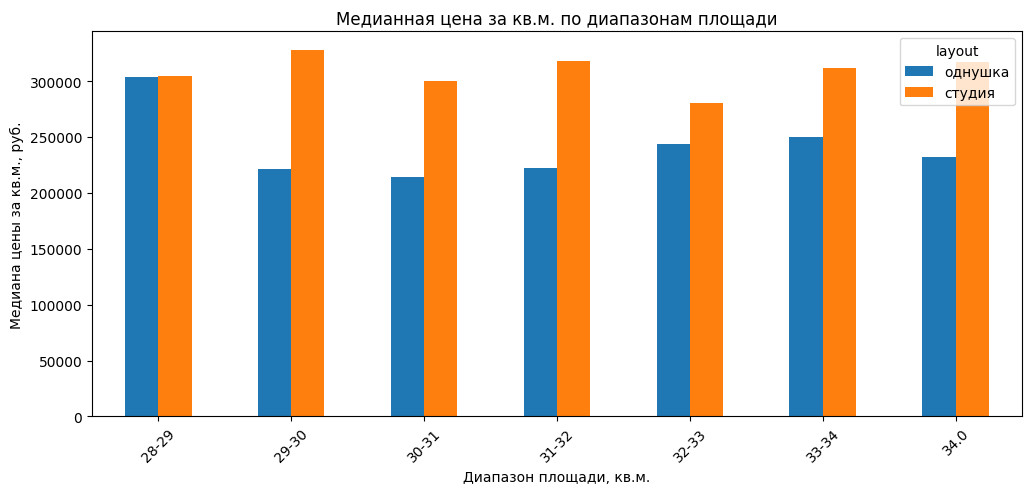

In [ ]:
pivot_flat = df_band.pivot_table(
    index='band', columns='layout',
    values='price_per_m2', aggfunc='median'
)
pivot_flat = pivot_flat.loc['28-29':]

pivot_flat.plot(kind='bar', figsize=(12, 5))
plt.ylabel('Медиана цены за кв.м., руб.')
plt.xlabel('Диапазон площади, кв.м.')
plt.title('Медианная цена за кв.м. по диапазонам площади')
plt.xticks(rotation=45);


В диапазоне 28-29 кв.м. медианные цены за квадратный метр у однушек и студий практически совпадают и находятся на довольно высоком уровне (около 304-305 тыс. руб.).

При дальнейшем увеличении площади однушки дешевеют, цена за квадратный метр падает. У студий же четкой тенденции к снижению не наблюдается.

Можно предположить, что цена за квадратный метр в целом снижается с ростом площади, однако даже при одинаковой площади разброс цен сохраняется. Это означает, что на стоимость влияют и другие факторы. Посмторим медианные цены за кв.м. в диапазоне от 25 до 35 кв.м.

In [ ]:
df_band.groupby('layout')['price_per_m2'].median().reset_index()

,layout,price_per_m2
0,однушка,243161.0
1,студия,312910.0


Если смотреть на сводку по всему диапазону 25-30 кв.м, то однушка: 243 161 руб./кв.м., а студия: 312 910 руб./кв.м. Кажется, что планировка студий сама по себе дает наценку.

In [ ]:
df_band.groupby(['layout', 'type'])['price_per_m2'].median().reset_index()

,layout,type,price_per_m2
0,однушка,Вторичка,226764.0
1,однушка,Новостройка,285714.0
2,студия,Вторичка,273214.0
3,студия,Новостройка,324095.0


В диапазоне 25-30 кв.м. самой дорогой категорией являются студии в новостройках (324 тыс. руб./кв.м.)

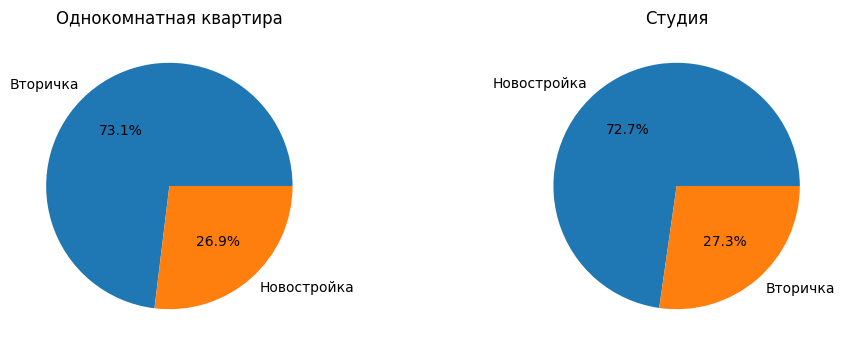

In [ ]:
second_band = df_band[df_band['layout']=='однушка']
new_band = df_band[df_band['layout']=='студия']
o_counts = second_band['type'].value_counts()
s_counts = new_band['type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].pie(o_counts, labels=o_counts.index, autopct='%1.1f%%')
axes[0].set_title('Однокомнатная квартира')

axes[1].pie(s_counts, labels=s_counts.index, autopct='%1.1f%%')
axes[1].set_title('Студия');

Из диаграм видно, что застройщики практически не строят полноценные однокомнатные квартиры такого маленького метража, они проектируют под него студии. На вторичном рынке наоборот, студий почти нет. Именно структура рынка скорее всего объясняет разрыв в медианных ценах за кв.м.



In [ ]:
# Посмотрим медианную площадь и цену за кв.м. для разной планировки в новостройке
df[df['type']=='Новостройка'].groupby('layout')[['price_per_m2', 'area']].mean().round(2).reset_index()

,layout,price_per_m2,area
0,однушка,290832.11,41.56
1,студия,328793.99,30.15


In [ ]:
# Посмотрим медианную площадь и цену за кв.м. для разной планировки во вторичке
df[df['type']=='Вторичка'].groupby('layout')[['price_per_m2', 'area']].mean().round(2).reset_index()

,layout,price_per_m2,area
0,однушка,242967.04,37.43
1,студия,254233.69,21.30


Таким образом, мы видим, что студия всего получается дороже за кв.м.

###**Вывод по главе 2**

1. Основная доля на рынке однокомнатных квартир и студий приходится на **однокомнатные (77%)**, студии занимают **23%**.

2. Студии чаще встречаются на вторичном рынке (**в 55% случаев**), однокомнатные в новых домах (**в 58%**).

3. Медианный размер объекта из выборки **36.9 кв.м.**, медианная цена за кв.м. **260 тыс.р.**, медианная цена объекта **9.8 млн. р.**

4. Если рассматривать студии и однокомнатные квартиры по отдельности, картина такая:
 - Для однокомнатной квартиры медианные значения площади - **38.9 кв.м**, цены за кв.м. - **257 тыс.р.**, цены - **10 млн.р.**
 - Для студии медианные значения площади - **27.4 кв.м**, цены за кв.м. - **286 тыс.р.**, цены - **7.8 млн.р.**

5. Жилье в новых домах имеет более высокую медианную цену за кв.м. В старом фонде медиана **236 тыс.р.**, в новом - **279 тыс.р.**

6. При сравнении студий и однокомнатных квартир одинакового метража (в диапазоне 25–35 кв.м.) студии выходят дороже: **313 тыс.р./кв.м. против 243 тыс.р./кв.м.** Это можно связать с тем, что в таком метраже на рынке больше студий в новостройках, тогда как однокомнатные квартиры этой площади чаще встречаются на вторичном рынке.

7. **Медианная цена за кв.м. у студий выше, чем у однокомнатных**, и в новостройках (**329 против 291 тыс.**), и на вторичке (**254 против 243 тыс.**).

8. В выборке присутствует **премиум-сегмент (6% от всей выборки)**.

9. Премиум-квартиры чаще встречаются **в новостройках**.

10. Медианная площадь премиум-квартир **38.2 кв.м.** Медианная цена за кв.м. - **449 тыс.р.**

11. В премиум-сегменте **вторичка немного дороже новостроек**: медианная цена за кв.м. выше примерно **на 1.5%**, что незначимо при данной выборке.

12. В премиум-сегменте однокомнатные квартиры стоят **469 тыс.р. за кв.м.**, а студии **420 тыс.р. за кв.м.**

###**3 Ценообразование на рынке**

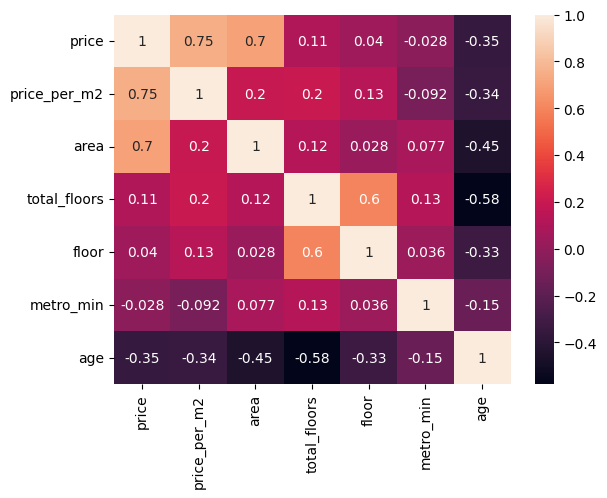

In [ ]:
num_cols = ['price', 'price_per_m2', 'area', 'total_floors', 'floor', 'metro_min', 'age']
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True);

Самая сильная связь у площади и цены r = 0.7, что логично, чем больше квартира, тем она дороже. Возраст дома связан с ценой отрицательно r = -0.36. Площадь и цена за кв.м. имеют слабую положительную связь r = 0.2, возможно за счет премиум-сегмента повышается цена за кв.м. при увеличении площади. Этажность и цена за кв.м. имеют положительную связь r = 0.2, то есть в высотных домах цена за метр выше. Этаж и близость метро слабо влияют на цену за кв.м. (r = 0.13 и r = -0.1).

Заметная отрицательная связь между возрастом дома и высотность дома r = -0.58. Высотки обычно новостройки, поэтому чем выше дом, тем он моложе. Умеренная отрицательная связь r = -0.45 между площадью и возрастом дома.
Связь между этажностью и близостью метро слабая	r = 0.13.	Высокие дома чуть чаще стоят далеко от метро. Между близостью метро и возрастом дома слабая отрицательная связь r = -0.15. Чем старее дом, тем он чуть ближе к метро.


**3.1 Влияение метро**

In [ ]:
# Медианные значения цен за кв.м. в зависимости от наличия рядом метро
metro_med = df.groupby('has_metro')['price_per_m2'].median()
metro_med.reset_index()

,has_metro,price_per_m2
0,False,248320.0
1,True,271820.0


In [ ]:
with_m = metro_med.loc[True]
not_m = metro_med.loc[False]
print(f'Медианная цена квартиры рядом с метро выше на {with_m - not_m:.2f} и {(with_m/not_m - 1)*100:.2f}%')

Медианная цена квартиры рядом с метро выше на 23500.00 и 9.46%


Наличие метро рядом повышает цену.

In [ ]:
# Уникальное количество значений времени до метро
df['metro_min'].value_counts().reset_index()

,metro_min,count
0,31.0,1069
1,20.0,803
2,15.0,751
3,30.0,619
4,10.0,466
5,5.0,2
6,2.0,1
7,3.0,1
8,6.0,1


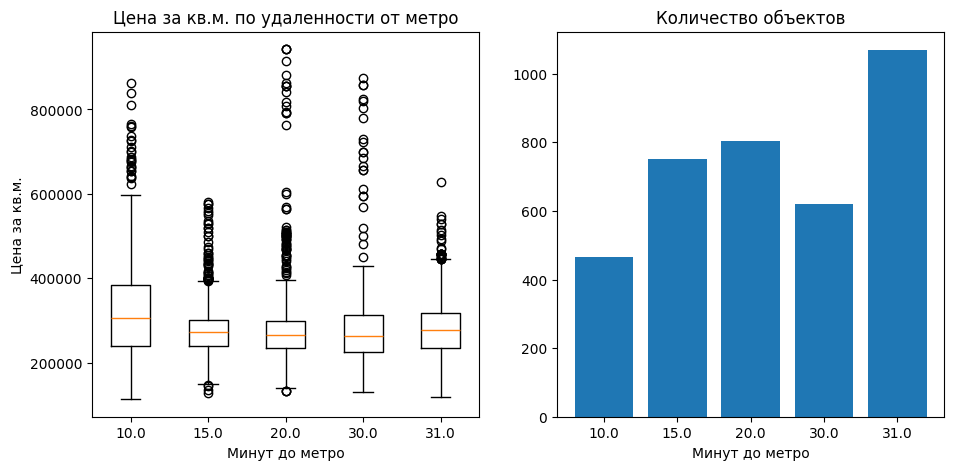

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

df_metro = df[df['metro_min'] >= 10].copy()
categor = sorted(df_metro['metro_min'].unique())
data_plot = [df_metro[df_metro['metro_min'] == i]['price_per_m2'] for i in categor]

axes[0].boxplot(data_plot, tick_labels=[str(i) for i in categor])
axes[0].set_title('Цена за кв.м. по удаленности от метро')
axes[0].set_xlabel('Минут до метро')
axes[0].set_ylabel('Цена за кв.м.')

counts = df_metro['metro_min'].value_counts().sort_index()
axes[1].bar([str(m) for m in counts.index], counts.values)
axes[1].set_title('Количество объектов')
axes[1].set_xlabel('Минут до метро');

In [ ]:
df[df['metro_min']>=10].groupby('metro_min')['price_per_m2'].median().reset_index()

,metro_min,price_per_m2
0,10.0,306199.5
1,15.0,271820.0
2,20.0,264484.0
3,30.0,262709.0
4,31.0,276968.0


От 10 до 30 минут цена падает, а на 31-й минуте снова растет.
В категорию «от 31 мин» попало много объектов (более 1000). Это связано
с тем, что на Авито есть отдельная группа «от 31 мин», куда входят
объекты с любым временем ходьбы от 31 минуты и больше.

Эта группа неоднородная, в неё могли попасть и сильно удаленные от метро объекты. На цену в этой группе могли повлиять и другие
факторы.

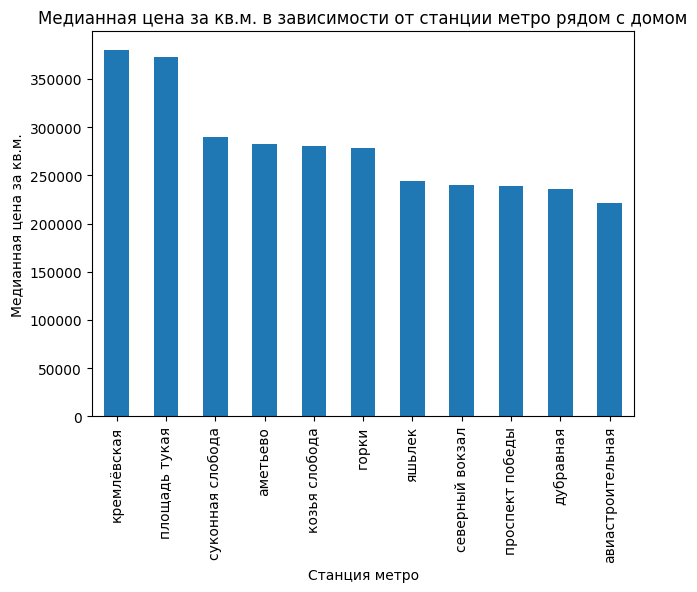

In [ ]:
metro_top = df[~(df['metro_nearest']=='неизвестное')].groupby('metro_nearest')['price_per_m2'].median().sort_values(ascending=False)

metro_top.plot(kind='bar', figsize=(7, 5))
plt.title('Медианная цена за кв.м. в зависимости от станции метро рядом с домом')
plt.xlabel('Станция метро')
plt.ylabel('Медианная цена за кв.м.');

In [ ]:
# Медианная цена за кв.м. в зависимости от станции метро рядом
metro_top.reset_index()

,metro_nearest,price_per_m2
0,кремлёвская,380387.0
1,площадь тукая,373000.0
2,суконная слобода,289565.0
3,аметьево,282989.0
4,козья слобода,280103.0
5,горки,278673.0
6,яшьлек,244656.0
7,северный вокзал,240000.0
8,проспект победы,238488.0
9,дубравная,236316.0


Кремлевская, площадь Тукая имеют медианную цену за кв.м. 373 и 380 тыс.р.

Суконная слобода, аметьево, козья слобода и горки	медианную цену за кв.м. в районе 290-279 тыс.р.
289565.0

Яшьлек, северный вокзал, проспект победы, дубравная и авиастроительная 240-221 тыс.р. за кв.м.

In [ ]:
# Проверим количество объявлений квартир рядом с метро и общее количество объявлений по районам
df.groupby('district')['has_metro'].agg(['sum', 'count']).reset_index().rename(columns={'sum':'Количество с метро', 'count':'Общее количество'})

,district,Количество с метро,Общее количество
0,авиастроительный,297,300
1,вахитовский,521,522
2,кировский,262,514
3,московский,170,198
4,ново-савиновский,322,433
5,приволжский,744,1191
6,советский,1335,2358


Для сравнения возьмем только районы, где количество объектов с метро и без большое.

In [ ]:
# Посмотри как наличие метро рядом влияет на медианноую цену за кв.м. по району
good_districts = ['кировский', 'ново-савиновский', 'приволжский', 'советский']

df[df['district'].isin(good_districts)].groupby(['district', 'has_metro'])['price_per_m2'].agg(['median', 'count'])


median  count
district         has_metro                 
кировский        False      207170.5    252
                 True       263935.0    262
ново-савиновский False      287475.0    111
                 True       257143.0    322
приволжский      False      208200.0    447
                 True       244826.0    744
советский        False      258145.0   1023
                 True       283798.0   1335

Три района из четырёх показывают, что с метро дороже. Ново-Савиновский исключение. Это может быть связано с тем, что в этом районе больше новостроек, которые далеко от метро.

In [ ]:
# Посмотрим медианную цену и количество для каждого типа жилья в зависимости от наличия рядом метро в Ново-Савиновском районе
df[df['district']=='ново-савиновский'].groupby(['has_metro', 'type'])['price_per_m2'].agg(['median', 'size'])

median  size
has_metro type                       
False     Вторичка     250288.0    74
          Новостройка  375990.0    37
True      Вторичка     247192.0   276
          Новостройка  383333.5    46

В группе «без метро» новостроек больше (по доле), чем в группе «с метро». Это и объясняет аномалию, новостройки дороже, они тянут медиану вверх.

**3.2 Влияние возраста дома**

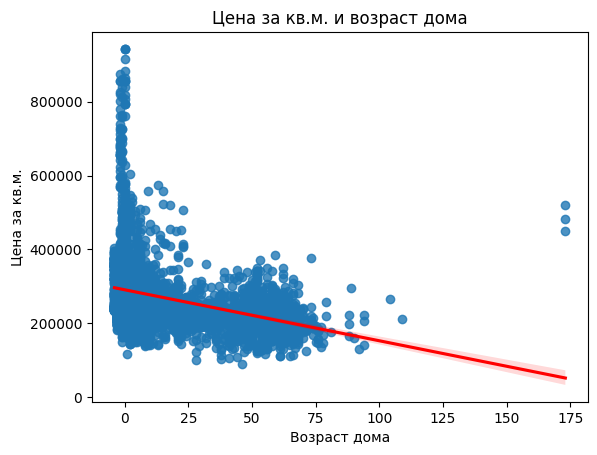

In [ ]:
sns.regplot(data=df, x = 'age', y ='price_per_m2', line_kws={'color': 'red'})
plt.title('Цена за кв.м. и возраст дома')
plt.xlabel('Возраст дома')
plt.ylabel('Цена за кв.м.');

С ростом возраста дома цена за метр падает, чем старше дом,
тем дешевле квадратный метр.

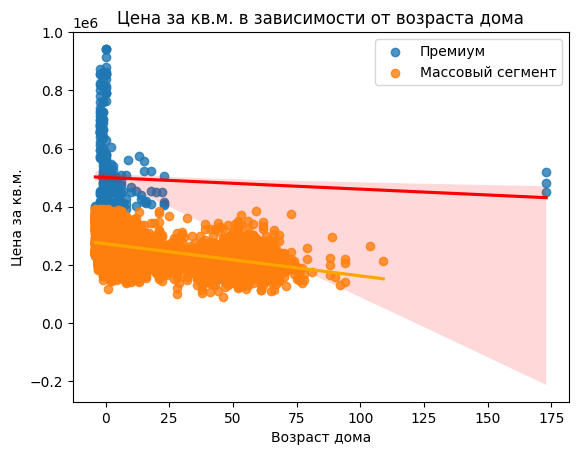

In [ ]:
sns.regplot(data=df[df['is_premium']], x = 'age', y ='price_per_m2', line_kws={'color': 'red'}, label='Премиум')
sns.regplot(data=df[~df['is_premium']], x = 'age', y ='price_per_m2', line_kws={'color': 'orange'}, label='Массовый сегмент')
plt.title('Цена за кв.м. в зависимости от возраста дома')
plt.xlabel('Возраст дома')
plt.ylabel('Цена за кв.м.')
plt.legend();

Разбили выборку на массовый и премиум-сегменты, в обоих
случаях цена за кв.м. падает с ростом возраста дома, однако в премиум-сегменте эта тенденция выражена слабее.

In [ ]:
# Посмотрим медианные цены за кв.м. у квартир для разных возрастных групп домов
df[~(df['age_bin']=='неизвестно')].groupby('age_bin')['price_per_m2'].median().sort_values(ascending=False).reset_index()

,age_bin,price_per_m2
0,строится,283083.0
1,0-5,269027.0
2,6-15,251041.5
3,16-30,227273.0
4,31-50,216206.5
5,50+,212389.0


Медианная цена за кв.м. монотонно снижается с ростом возраста дома от 283 тыс. руб. в ещё строящихся объектах до 212 тыс. руб. в домах старше 50 лет.

In [ ]:
# Посмотрим медианные цены за кв.м. у квартир для разных возрастных групп домов премиума
mask = df['is_premium'] & ~(df['age_bin']=='неизвестно')
df[mask].groupby('age_bin')['price_per_m2'].agg(['median', 'count']).sort_values(by='median', ascending=False).reset_index()

,age_bin,median,count
0,50+,482742.0,3
1,0-5,451269.5,164
2,6-15,446429.0,25
3,строится,442450.5,158
4,16-30,418182.0,11


In [ ]:
# Посмотрим какая корреляция между возрастом дома и ценой за кв.м. для премиума
df[df['is_premium']][['age', 'price_per_m2']].corr()

,age,price_per_m2
age,1.000000,-0.050834
price_per_m2,-0.050834,1.000000


Есть 3 дорогих объекта в старом фонде с медианой 483 тыс.р. за кв.м. Квартиры в домах возрастом до 5 лет имеют медиану 451 тыс.р. за кв.м. Коэффициент Пирсона для равен r = -0.05, то есть в премиум-сегменте линейная связь возраста дома и цены за кв.м. практически отсутствует.

**3.3 Этажность дома и этаж**

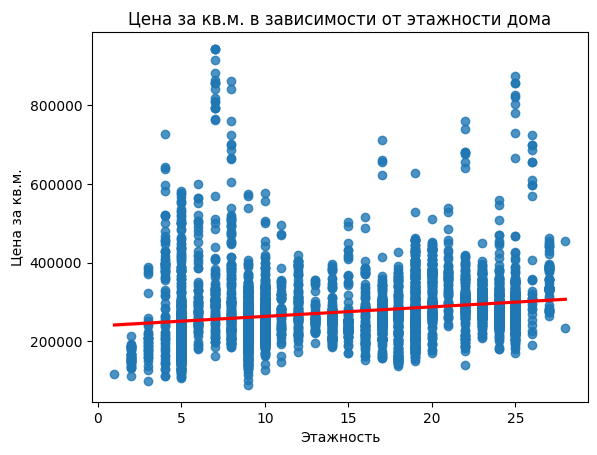

In [ ]:
sns.regplot(data=df, x = 'total_floors', y ='price_per_m2', line_kws={'color': 'red'})
plt.title('Цена за кв.м. в зависимости от этажности дома')
plt.xlabel('Этажность')
plt.ylabel('Цена за кв.м.');

In [ ]:
# Посмотрим значения медианных цен за кв.м. в зависимости от этажности дома
df.groupby('floors_bin')['price_per_m2'].median().sort_values().reset_index()

,floors_bin,price_per_m2
0,до 5,208469.0
1,6-9,247887.0
2,10-16,254537.0
3,17+,279850.0


Чем выше дом, тем дороже метр. Это согласуется с тем, что высотки обычно новостройки, а новостройки дороже.

In [ ]:
median_1floor = df[df['floor'] == 1]['price_per_m2'].median()
median_med_floor = df[(df['floor'] > 1) & (df['floor'] < df['total_floors'])]['price_per_m2'].median()
median_last_floor = df[df['floor'] == df['total_floors']]['price_per_m2'].median()
print(f'Медианная цена за кв. м. у квартир на 1 этажах {median_1floor}')
print(f'Медианная цена за кв. м. у квартир на средних этажах {median_med_floor}')
print(f'Медианная цена за кв. м. у квартир на последних этажах {median_last_floor}')

Медианная цена за кв. м. у квартир на 1 этажах 221053.0
Медианная цена за кв. м. у квартир на средних этажах 266466.0
Медианная цена за кв. м. у квартир на последних этажах 239967.0


Средний этаж самый дорогой.

**3.4 Влияние района**

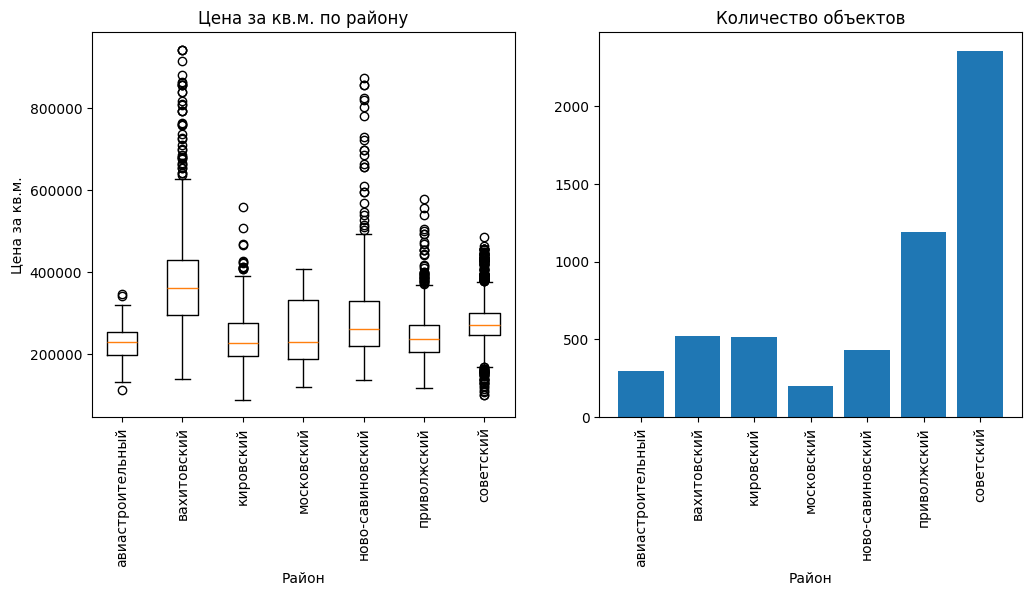

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

categor = sorted(df['district'].dropna().astype(str).unique())
data_plot = [df[df['district'] == i]['price_per_m2'] for i in categor]

axes[0].boxplot(data_plot, tick_labels=[str(i) for i in categor])
axes[0].set_title('Цена за кв.м. по району')
axes[0].set_xlabel('Район')
axes[0].set_ylabel('Цена за кв.м.')
axes[0].tick_params(axis='x', rotation=90)

counts = df['district'].value_counts().sort_index()
axes[1].bar([str(m) for m in counts.index], counts.values)
axes[1].set_title('Количество объектов')
axes[1].set_xlabel('Район')
axes[1].tick_params(axis='x', rotation=90);

In [ ]:
# Посмотрим какие медианные цена за кв.м. и какое количество объявлений в каждом районе
district_med = df.groupby('district')['price_per_m2'].agg(['median', 'count']).sort_values('median', ascending=False)
district_med.reset_index()

,district,median,count
0,вахитовский,360917.5,522
1,советский,272346.5,2358
2,ново-савиновский,261386.0,433
3,приволжский,238390.0,1191
4,московский,231032.0,198
5,авиастроительный,229519.5,300
6,кировский,227492.5,514


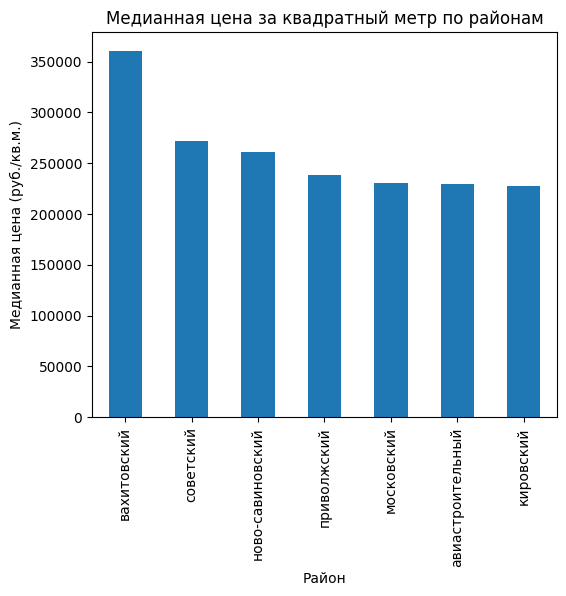

In [ ]:
district_med['median'].plot(kind='bar', figsize=(6, 5))
plt.title('Медианная цена за квадратный метр по районам')
plt.xlabel('Район')
plt.ylabel('Медианная цена (руб./кв.м.)');

Вахитовский (360 918 р./кв.м.) - самый дорогой. Советский на втором месте (272 347 р./кв.м.), хотя советский район большой и неоднородный. Возможно, в нём много новостроек. На третьем месте Ново-Савиновский (261 386 р./кв.м.)

Московский, Авиастроительный и Кировский - самые недорогие (231-227 тыс. р./кв.м.).

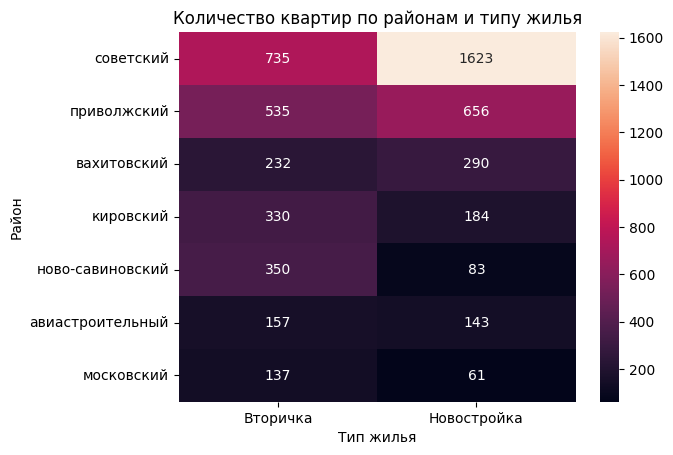

In [ ]:
pivot = pd.crosstab(df['district'], df['type'])
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

sns.heatmap(pivot, fmt='d', annot=True)
plt.title('Количество квартир по районам и типу жилья')
plt.xlabel('Тип жилья')
plt.ylabel('Район');

Советский район самый крупный  по числу объявлений (735 вторички и 1 623 новостройки). Состоит из одних новостроек, что объясняет его второе место по цене за кв.м.

Второй по объему район Приволжский (535 вторички и 656 новостроек). Самый сбалансированный район по структуре.

Вахитовский (232 вторички и 290 новостроек).

Кировский район с перекосом во вторичку (330 вторички и 184 новостройки).

Ново-Савиновский почти чистая вторичка (350 вторички и 83 новостройки), но по цене за кв.м. третье место.

Авиастроительный достаточно сбалансированный (157 вторички и 143 новостройки).

Московский (137 вторички и 61 новостройка).

In [ ]:
# Проверим сколько премиума и массового сегмента в каждом районе
df.groupby(['district', 'is_premium'])['price_per_m2'].count().reset_index().rename(columns={'price_per_m2': 'count'})

,district,is_premium,count
0,авиастроительный,False,300
1,вахитовский,False,340
2,вахитовский,True,182
3,кировский,False,501
4,кировский,True,13
5,московский,False,186
6,московский,True,12
7,ново-савиновский,False,385
8,ново-савиновский,True,48
9,приволжский,False,1166


Премиум это почти только вахитовский район.

Ново-Савиновский — на втором месте по доле премиума (11%) после Вахитовского.

Авиастроительный - единственный район без премиума.

In [ ]:
# Проверим какая медианная цена за кв.м. в Ново-Савиновском районе без премиума
df[df['district'] == 'ново-савиновский'].groupby('is_premium')['price_per_m2'].median().reset_index()

,is_premium,price_per_m2
0,False,252600.0
1,True,506876.0


Премиум в Ново-Савиновском в два раза дороже массового сегмента. И таких объектов в раййоне 11%. Это и объясняет 3 место по цене за кв.м. среди всех районов.

In [ ]:
# Проверим медианный возраст домов
df.groupby('district')['age'].median().sort_values().reset_index()

,district,age
0,советский,-1.0
1,вахитовский,0.0
2,приволжский,1.0
3,авиастроительный,2.0
4,кировский,5.0
5,ново-савиновский,20.0
6,московский,48.0


В Советском районе медиана -1, то есть больше половины объектов это строящиеся дома. Медианный возраст домов в вахитовском - 0 лет.

Ново-савиновский и московский «старые» районы, медианный возраст 20 и 48 лет соответственно.

**3.5 Влияние ЖК**

In [ ]:
# Проверим влияение наличия ЖК на цену за кв.м.
med_rc = df.groupby('has_residential_complex')['price_per_m2'].median()
med_rc.reset_index()

,has_residential_complex,price_per_m2
0,False,236111.0
1,True,279616.5


In [ ]:
print(f'Квартиры в ЖК дороже на {(med_rc[True]/med_rc[False]-1)*100:.0f}%')

Квартиры в ЖК дороже на 18%


In [ ]:
# Посмотрим на топ 10 самый дорогих жк (медиана цены за кв.м.)
df.groupby(['residential_complex', 'district'])['price_per_m2'].median().sort_values(ascending=False).head(10).reset_index()

,residential_complex,district,price_per_m2
0,ЖК «Заман»,вахитовский,855857.5
1,ЖК «Заря‎»,вахитовский,701057.0
2,Яр Парк,ново-савиновский,699000.0
3,ЖК «Резиденция Баркли Дан»,вахитовский,668494.0
4,Клубный дом «Авторы на Астрономической»,вахитовский,636711.0
5,Клубный дом «Авторы на Петербургской»,вахитовский,535365.0
6,ЖК «Променад»,вахитовский,502464.5
7,ЖД «Ноты»,вахитовский,500231.0
8,Клубный дом «Шаляпина XV»,приволжский,497272.5
9,ЖК «Академик»,вахитовский,492033.0


ЖК Заман самый дорогой ЖК города. При этом 8/10 дорогих ЖК находятся в вахитовском районе.

**3.6 Портреты премиум-объекта и объекта из массового сегмента**

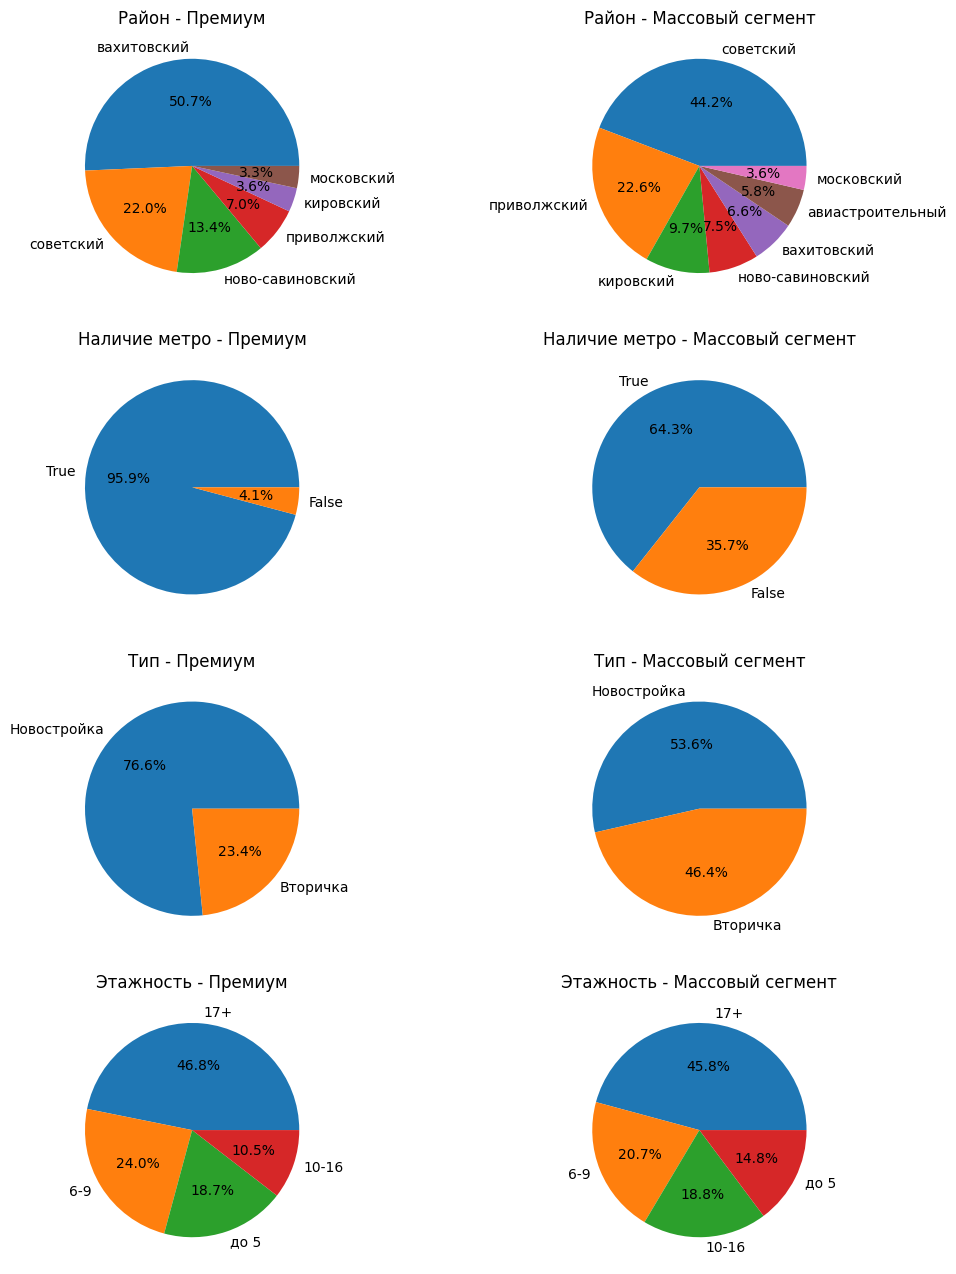

In [ ]:
cols = ['district', 'has_metro', 'type', 'floors_bin']

cols_dict = {
    'district':   'Район',
    'has_metro':  'Наличие метро',
    'type':       'Тип',
    'floors_bin': 'Этажность',
}

df_p = df[df['is_premium'] == True]
df_np = df[df['is_premium'] == False]

fig, axes = plt.subplots(len(cols), 2, figsize=(12, 4*len(cols)))

for i, col in enumerate(cols):
    counts_p = df_p[col].value_counts()
    axes[i, 0].pie(counts_p, labels=counts_p.index, autopct='%1.1f%%')
    axes[i, 0].set_title(f'{cols_dict[col]} - Премиум')

    counts_np = df_np[col].value_counts()
    axes[i, 1].pie(counts_np, labels=counts_np.index, autopct='%1.1f%%')
    axes[i, 1].set_title(f'{cols_dict[col]} - Массовый сегмент')

Премиум сильно сконцентрирован в Вахитовском (50.7%), а массовый сегмент в Советском (44.2%).

Премиум почти рядом с метро в 95.9% случаев, в массовый сегмент в 64.3%.

Премиум в основном новостройки (76.6%), массовый более сбалансирован (53.6% новостройки, 46.4% вторичка).

Оба сегмента примерно одинаково тяготеют к высоким этажам (17+ этажей около 46%).

### **Вывод по главе 3**

1) Квартиры в домах где указано рядом метро по медиане **дороже на 9.5%**. При этом связь между временем до метро и ценой кв.м. **слабая**, коэффициент корреляции Пирсона равен **-0.1**. Наблюдается тенденция снижения медианной цены за кв.м. при увеличении времени ходьбы до метро с 10 до 31 минуты и более с **306 тыс. р.** до **277 тыс. р.**

2) Самые «дорогие» станции - **Кремлевская** и **Площадь Тукая**, рядом с этими станциями медианные цены **373 и 380 тыс.р.** за кв.м. соответственно. Самая «дешевая» станция - **Авиастроительная** - **221 тыс.р.** за кв.м.

3) **Ново-Савиновский район** единственный, где объекты рядом с метро **дешевле**, чем без метро (**257 тыс.р.** за кв.м. против **287 тыс.р.**). Это объясняется тем, что в группе "без метро" новостроек больше по доле (**33%** новостроек без метро и **14%** новостроек, где метро есть).

4) Коэффициент Пирсона для возраста дома и цены за кв.м. равен **-0.39**, то есть аблюдается отрицательная связь: чем **старше** дом, тем **ниже** медианная цена за кв.м.. Это согласуется с монотонным снижением медианы от **283 тыс. руб.** в строящихся объектах до **212 тыс. руб.** в домах старше 50 лет.

5) Корреляция Пирсона между этажностью дома и ценой за кв.м. составляет **r = 0.20** (слабая положительная связь). Наблюдается монотонный рост медиан с **208** до **280 тыс. руб./кв.м.**

6) Линейная связь между этажем и ценой за кв.м. **слабая** (**r = 0.13**). Однако при разбивке по категориям видна **нелинейная закономерность**: средний этаж дороже (**266 тыс. руб./кв.м.**) первого (**221 тыс.р.**) и последнего (**240 тыс.р.**).

7) Самые дорогие районы это **Вахитовский** (**361 тыс.р.** за кв.м.), **Советский** (**272 тыс.р.** за кв.м.) и **Ново-Савиновский** (**261 тыс.р.** за кв.м.).

8) **Советский район** самый крупный по числу объявлений (**735 вторички** и **1 623 новостройки**).

9) **Ново-Савиновский** почти чистая вторичка по числу объявлений (**350 вторички** и **83 новостройки**), но по цене за кв.м. занимает **третье место** среди районов. Это во многом связано с высокой долей премиума **(11%)**, второй показатель после Вахитовского. Медиана премиума **507 тыс. руб./кв.м.**, массового сегмента **253 тыс. руб./кв.м.**

10) У квартиры с ЖК медианное значение цены за кв.м. выше на **18%**.

11) В премиум-сегменте корреляция возраста дома и цены за кв.м. составила **r = -0.05**, линейной связи практически нет. Это подтверждает ранее сделанный вывод: разница между вторичкой и новостройками в премиуме носит **случайный характер**.

12) **ЖК Заман** самый дорогой ЖК города (медиана **856 тыс.р.** за кв.м.). При этом **8/10** самых дорогих ЖК находятся в вахитовском районе.

13) Топ-3 премиальных ЖК: **«Заман»**, **«Заря»** и **«Яр Парк»**.

14) Премиальные объекты находятся рядом с метро в **95.9%** случаев.

